# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Daffa Aufa Afif | 5054251022 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, scipy, dll)
import warnings
warnings.filterwarnings('ignore', message='Unable to import Axes3D')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

SEED = 42
plt.rcParams['figure.figsize'] = (8, 5)
sns.set_style('whitegrid')

In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, jumlah missing value, dan jumlah baris duplikat.
# Perhatikan apakah ada kolom yang seluruhnya kosong.
df = pd.read_csv('Live.csv')

print('5 baris pertama:')
print(df.head().to_string(index=False))
print('\nUkuran dataset:', df.shape)
print('\nTipe data:\n', df.dtypes.to_string())
print('\nStatistik deskriptif (fitur numerik):')
print(df.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']].round(2).to_string())
print('\nJumlah missing value per kolom:\n', df.isna().sum().to_string())
print('\nJumlah baris duplikat (seluruh kolom):', df.duplicated().sum())
print('Jumlah baris duplikat (mengabaikan status_id):',
      df.duplicated(subset=[c for c in df.columns if c != 'status_id']).sum())
print('Jumlah status_id unik:', df['status_id'].nunique())

5 baris pertama:
 status_id status_type status_published  num_reactions  num_comments  num_shares  num_likes  num_loves  num_wows  num_hahas  num_sads  num_angrys  Column1  Column2  Column3  Column4
         1       video   4/22/2018 6:00            529           512         262        432         92         3          1         1           0      NaN      NaN      NaN      NaN
         2       photo  4/21/2018 22:45            150             0           0        150          0         0          0         0           0      NaN      NaN      NaN      NaN
         3       video   4/21/2018 6:17            227           236          57        204         21         1          1         0           0      NaN      NaN      NaN      NaN
         4       photo   4/21/2018 2:29            111             0           0        111          0         0          0         0           0      NaN      NaN      NaN      NaN
         5       photo   4/18/2018 3:22            213             0     

Ringkasan distribusi fitur hitungan:
               min  median    mean    max     std  skewness  persen_nol (%)
num_reactions    0    59.5  230.12   4710  462.63      3.74            1.72
num_comments     0     4.0  224.36  20990  889.64      9.03           30.06
num_shares       0     0.0   40.02   3424  131.60      7.10           55.48
num_likes        0    58.0  215.04   4710  449.47      3.92            1.79
num_loves        0     0.0   12.73    657   39.97      6.00           60.00
num_wows         0     0.0    1.29    278    8.72     18.25           75.29
num_hahas        0     0.0    0.70    157    3.96     20.31           83.91
num_sads         0     0.0    0.24     51    1.60     17.58           91.39
num_angrys       0     0.0    0.11     31    0.73     19.51           94.00


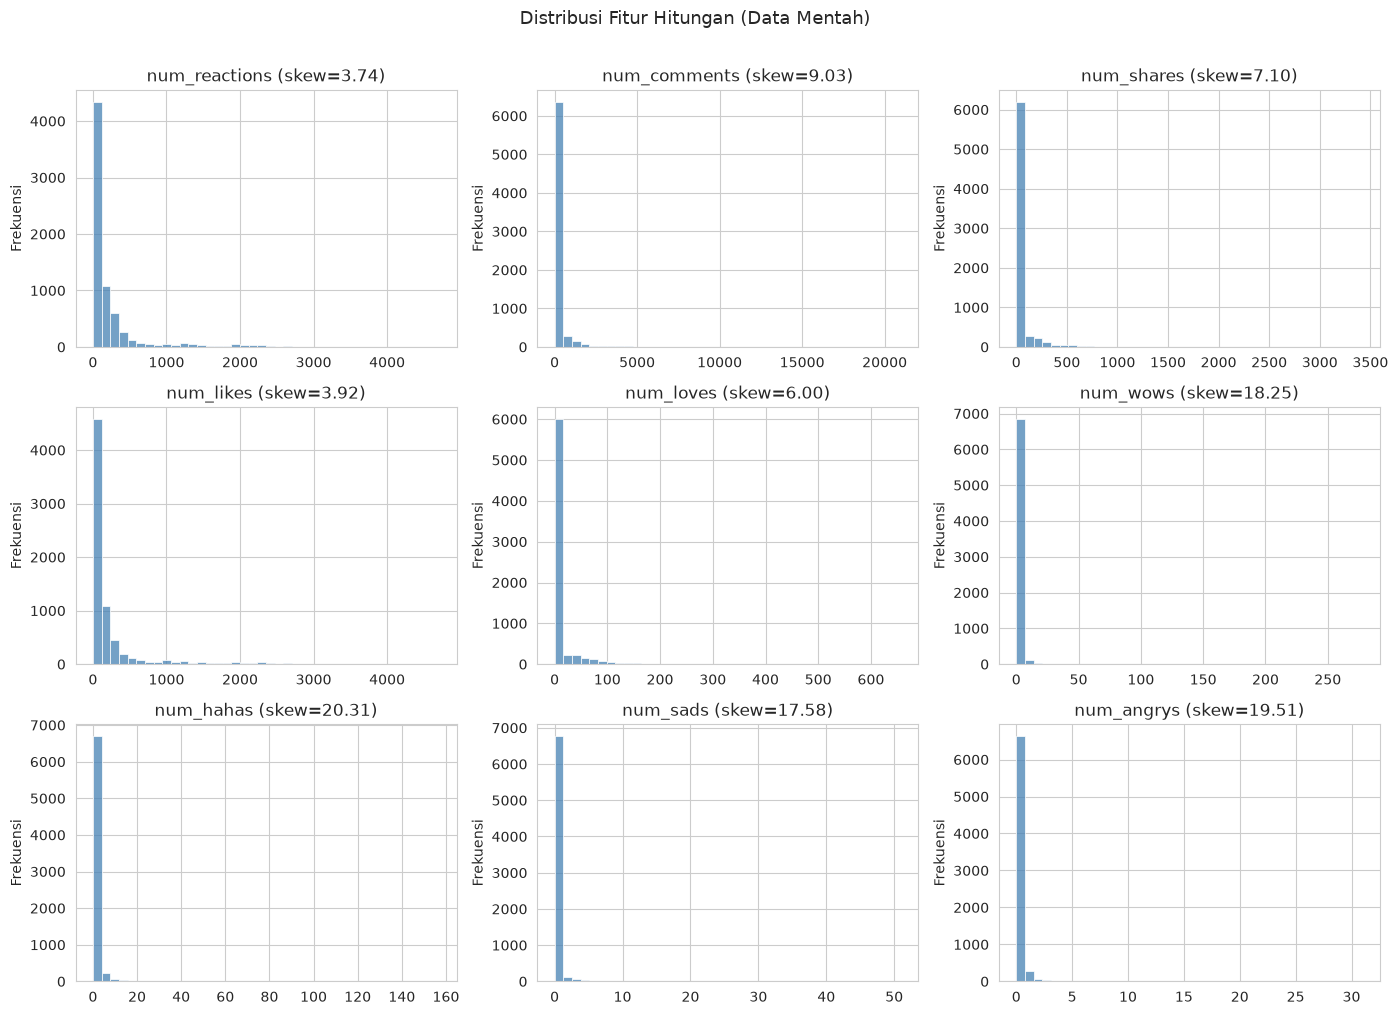

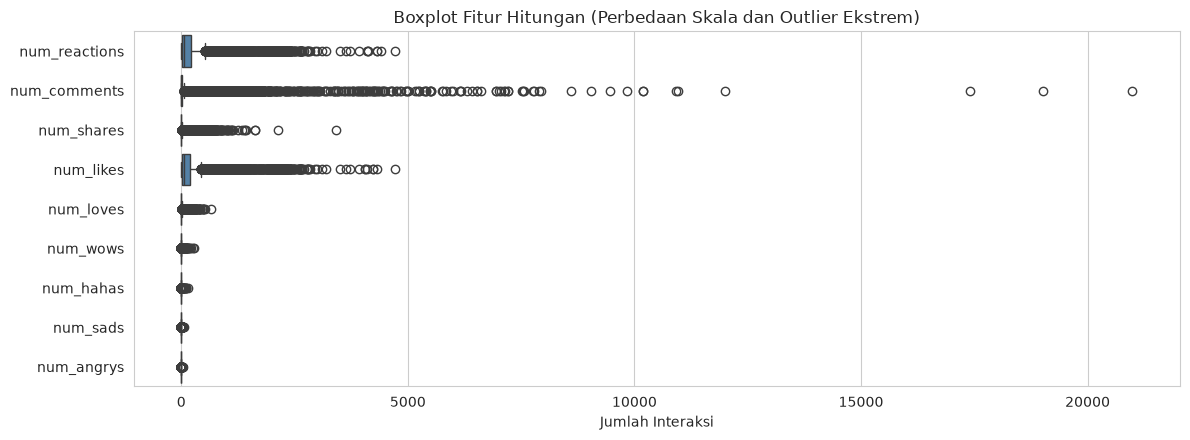

In [3]:
# Tampilkan distribusi fitur hitungan (histogram atau boxplot).
# Perhatikan skewness, proporsi nilai nol, dan perbedaan skala antar fitur (misalnya num_comments vs num_angrys), karena ini penting untuk tahap preprocessing.
num_cols = [
    'num_reactions', 'num_comments', 'num_shares', 'num_likes',
    'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys'
]

dist_summary = pd.DataFrame({
    'min': df[num_cols].min(),
    'median': df[num_cols].median(),
    'mean': df[num_cols].mean().round(2),
    'max': df[num_cols].max(),
    'std': df[num_cols].std().round(2),
    'skewness': df[num_cols].skew().round(2),
    'persen_nol (%)': ((df[num_cols] == 0).mean() * 100).round(2)
})
print('Ringkasan distribusi fitur hitungan:')
print(dist_summary.to_string())

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flatten(), num_cols):
    sns.histplot(df[col], bins=40, ax=ax, color='steelblue')
    ax.set_title(f'{col} (skew={df[col].skew():.2f})')
    ax.set_xlabel('')
    ax.set_ylabel('Frekuensi')
plt.suptitle('Distribusi Fitur Hitungan (Data Mentah)', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4.5))
sns.boxplot(data=df[num_cols], orient='h', color='steelblue')
plt.title('Boxplot Fitur Hitungan (Perbedaan Skala dan Outlier Ekstrem)')
plt.xlabel('Jumlah Interaksi')
plt.tight_layout()
plt.show()

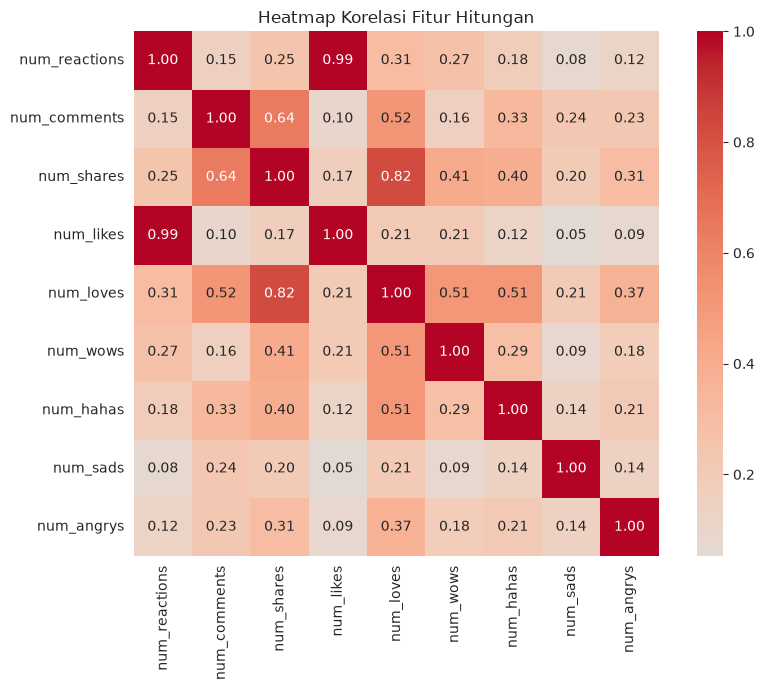

Korelasi num_reactions dengan num_likes: 0.9949
Baris dengan num_reactions == jumlah 6 reaksi: 7041 dari 7050 (selisih maks: 4)


In [4]:
# Tampilkan heatmap korelasi antar fitur hitungan.
# Perhatikan fitur-fitur yang berkorelasi sangat tinggi atau saling berkaitan secara definisi (redundan), karena memengaruhi perhitungan jarak pada clustering.
corr = df[num_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Heatmap Korelasi Fitur Hitungan')
plt.tight_layout()
plt.show()

sum_reactions = df[['num_likes', 'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']].sum(axis=1)
diff_reactions = (df['num_reactions'] - sum_reactions).abs()
print(f'Korelasi num_reactions dengan num_likes: {corr.loc["num_reactions", "num_likes"]:.4f}')
print(f'Baris dengan num_reactions == jumlah 6 reaksi: {(diff_reactions == 0).sum()} dari {len(df)} (selisih maks: {diff_reactions.max()})')

Jumlah posting dan proporsi reaksi emoji per tahun:
 year  jumlah_posting  posting_ber_emoji  proporsi_emoji_persen
 2012             589                  0                   0.00
 2013             500                  0                   0.00
 2014             233                  0                   0.00
 2015             337                  0                   0.00
 2016             588                400                  68.03
 2017            2253               1221                  54.19
 2018            2550               1473                  57.76


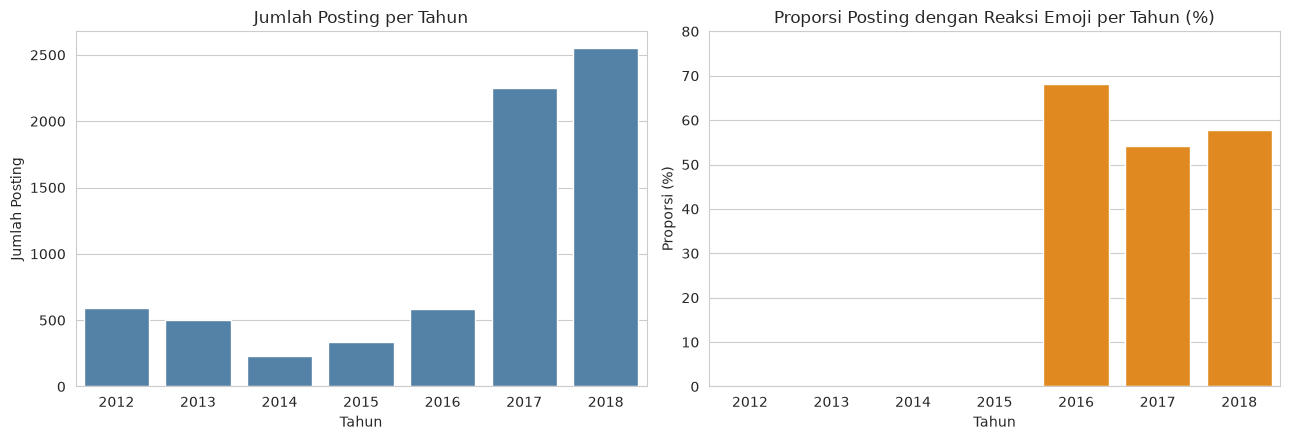

In [5]:
# Ubah kolom status_published menjadi datetime.
# Tampilkan jumlah posting dan proporsi posting yang memiliki reaksi emoji pada setiap tahun.
# Amati apakah ada perubahan pola dari tahun ke tahun.
df['status_published_dt'] = pd.to_datetime(df['status_published'])
df['year'] = df['status_published_dt'].dt.year

emoji_cols = ['num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
df['has_emoji'] = df[emoji_cols].sum(axis=1) > 0

yearly = df.groupby('year').agg(
    jumlah_posting=('status_id', 'count'),
    posting_ber_emoji=('has_emoji', 'sum'),
    proporsi_emoji_persen=('has_emoji', lambda x: round(x.mean() * 100, 2))
).reset_index()

print('Jumlah posting dan proporsi reaksi emoji per tahun:')
print(yearly.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=yearly, x='year', y='jumlah_posting', ax=axes[0], color='steelblue')
axes[0].set_title('Jumlah Posting per Tahun')
axes[0].set_xlabel('Tahun')
axes[0].set_ylabel('Jumlah Posting')

sns.barplot(data=yearly, x='year', y='proporsi_emoji_persen', ax=axes[1], color='darkorange')
axes[1].set_title('Proporsi Posting dengan Reaksi Emoji per Tahun (%)')
axes[1].set_xlabel('Tahun')
axes[1].set_ylabel('Proporsi (%)')
axes[1].set_ylim(0, 80)

plt.tight_layout()
plt.show()

Distribusi status_type:
             jumlah  persen (%)
status_type                    
photo          4288       60.82
video          2334       33.11
status          365        5.18
link             63        0.89

Median engagement berdasarkan status_type:
             num_likes  num_comments  num_shares
status_type                                     
link              48.0           1.0         0.0
photo             34.0           2.0         0.0
status           117.0          10.0         0.0
video            117.0          39.0        12.0


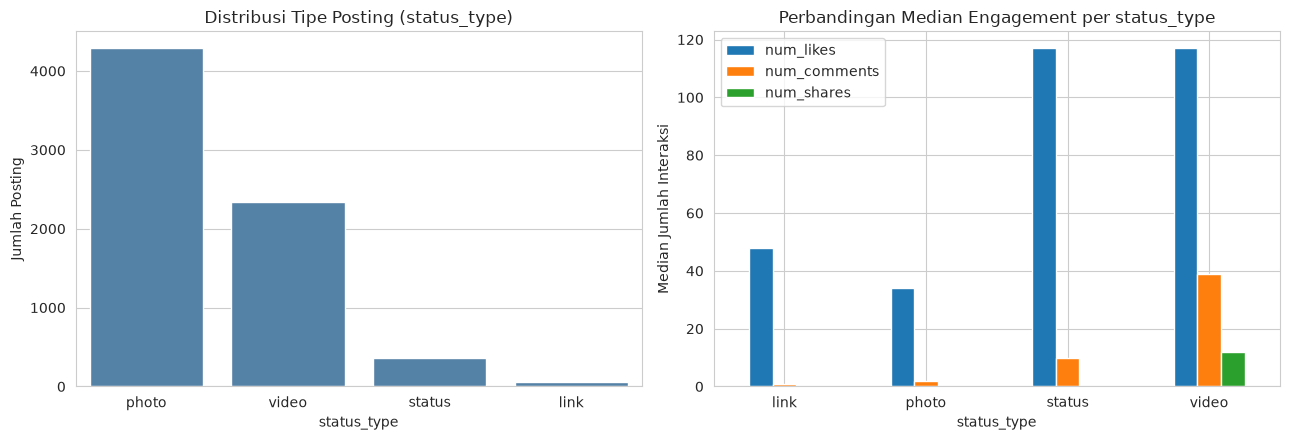

In [6]:
# Tampilkan distribusi status_type dalam bentuk bar plot.
# Bandingkan median num_likes, num_comments, dan num_shares untuk setiap status_type.
type_counts = df['status_type'].value_counts()
type_median = df.groupby('status_type')[['num_likes', 'num_comments', 'num_shares']].median()

print('Distribusi status_type:')
print(pd.DataFrame({'jumlah': type_counts, 'persen (%)': (type_counts / len(df) * 100).round(2)}).to_string())
print('\nMedian engagement berdasarkan status_type:')
print(type_median.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(x=type_counts.index, y=type_counts.values, ax=axes[0], color='steelblue')
axes[0].set_title('Distribusi Tipe Posting (status_type)')
axes[0].set_xlabel('status_type')
axes[0].set_ylabel('Jumlah Posting')

type_median.plot(kind='bar', ax=axes[1])
axes[1].set_title('Perbandingan Median Engagement per status_type')
axes[1].set_xlabel('status_type')
axes[1].set_ylabel('Median Jumlah Interaksi')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

In [7]:
# EDA tambahan: cek persentil atas (P95, P99, maks) untuk melihat seberapa ekstrem ekor distribusi
percentiles = df[num_cols].quantile([0.5, 0.9, 0.95, 0.99, 1.0]).T
percentiles.columns = ['P50 (Median)', 'P90', 'P95', 'P99', 'Max']
print('Persentil atas fitur hitungan:')
print(percentiles.round(1).to_string())

# Cek proporsi nilai nol pada gabungan seluruh reaksi emoji (num_emojis)
total_emoji = df[emoji_cols].sum(axis=1)
print(f'\nProporsi nol jika 5 kolom emoji digabung (num_emojis): {(total_emoji == 0).mean() * 100:.2f}%')

Persentil atas fitur hitungan:
               P50 (Median)    P90     P95     P99      Max
num_reactions          59.5  520.5  1239.6  2306.1   4710.0
num_comments            4.0  508.1  1210.6  4338.0  20990.0
num_shares              0.0  136.0   260.1   607.0   3424.0
num_likes              58.0  496.1  1160.1  2297.0   4710.0
num_loves               0.0   40.1    77.0   198.0    657.0
num_wows                0.0    2.0     4.0    16.0    278.0
num_hahas               0.0    2.0     4.0    12.0    157.0
num_sads                0.0    0.0     1.0     5.0     51.0
num_angrys              0.0    0.0     1.0     3.0     31.0

Proporsi nol jika 5 kolom emoji digabung (num_emojis): 56.11%


### Ringkasan Temuan EDA

Dataset awal terdiri dari 7.050 baris dan 16 kolom. Kolom `Column1` sampai `Column4` seluruhnya kosong (7.050 missing value), sedangkan kolom lainnya tidak memiliki missing value. Tidak ada baris duplikat jika seluruh kolom diperiksa karena `status_id` unik untuk setiap baris, tetapi ditemukan 54 baris duplikat jika `status_id` diabaikan.

Seluruh fitur hitungan sangat menceng ke kanan (*right-skewed*) dengan nilai skewness berkisar antara 3,74 (`num_reactions`) hingga 20,31 (`num_hahas`). Rentang nilainya juga sangat timpang: `num_comments` mencapai maksimum 20.990, sementara `num_angrys` maksimumnya hanya 31 dengan 94,00% data bernilai nol. Selain itu, `num_reactions` berkorelasi 0,9949 dengan `num_likes` dan pada 7.041 dari 7.050 baris nilainya persis sama dengan penjumlahan `num_likes` hingga `num_angrys`, sehingga bersifat redundan.

Berdasarkan tahun publikasi, posting pada tahun 2012–2015 seluruhnya memiliki 0% reaksi emoji karena fitur reaksi emoji baru diluncurkan Facebook pada tahun 2016. Mulai tahun 2016 hingga 2018, proporsi posting yang mendapat reaksi emoji melonjak menjadi 54,19%–68,03%. Dari sisi tipe posting, `photo` mendominasi (4.288 posting atau 60,82%), diikuti `video` (2.334 atau 33,11%). Namun, secara median, `video` memiliki interaksi paling aktif dengan median 117 like, 39 komentar, dan 12 share, jauh lebih tinggi dibanding `photo` yang hanya memiliki median 34 like, 2 komentar, dan 0 share.

# 2. Preprocessing

In [8]:
# Hapus kolom yang seluruhnya kosong.
# Periksa dan tangani baris duplikat (ingat bahwa status_id selalu unik untuk tiap baris).
# Periksa juga missing value dan outlier ekstrem, lalu tentukan penanganannya.
df_clean = df.drop(columns=['Column1', 'Column2', 'Column3', 'Column4', 'status_published_dt', 'year', 'has_emoji']).copy()

n_before = len(df_clean)
dup_cols = [c for c in df_clean.columns if c != 'status_id']
n_dup = df_clean.duplicated(subset=dup_cols).sum()
df_clean = df_clean.drop_duplicates(subset=dup_cols).reset_index(drop=True)

print(f'Baris sebelum hapus duplikat : {n_before}')
print(f'Duplikat ditemukan & dihapus : {n_dup}')
print(f'Baris setelah pembersihan    : {len(df_clean)}')
print(f'Total missing value tersisa  : {df_clean.isna().sum().sum()}')

# Catatan outlier: nilai ekstrem (misalnya posting viral dengan >10.000 komentar) merupakan fenomena asli
# dari aktivitas live selling dan bukan kesalahan pencatatan, sehingga tidak dibuang melainkan diredam
# dengan transformasi log1p pada tahap berikutnya.

Baris sebelum hapus duplikat : 7050
Duplikat ditemukan & dihapus : 54
Baris setelah pembersihan    : 6996
Total missing value tersisa  : 0


In [9]:
# Pisahkan status_type dan status_published (untuk interpretasi cluster pada tahap evaluasi) dari fitur yang akan dipakai untuk clustering.
# Hapus kolom yang tidak relevan untuk clustering (misalnya status_id).
# Periksa apakah ada fitur yang redundan (misalnya fitur yang merupakan penjumlahan fitur lain) atau yang sebagian besar bernilai nol.
# Pilih fitur yang akan dipakai untuk clustering. Pertimbangkan untuk menggabungkan fitur yang sparse.
# Catatan: K-Means dan Hierarchical Clustering berbasis jarak, sehingga semua fitur harus berupa angka.

meta_df = df_clean[['status_type', 'status_published']].copy()

emoji_cols = ['num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
df_clean['num_emojis'] = df_clean[emoji_cols].sum(axis=1)

selected_features = ['num_likes', 'num_comments', 'num_shares', 'num_emojis']
X_raw = df_clean[selected_features].copy()

print('Fitur terpilih untuk clustering:', selected_features)
print('Ukuran matriks fitur:', X_raw.shape)
print('\nRingkasan fitur terpilih (data asli):')
summary_sel = pd.DataFrame({
    'median': X_raw.median(),
    'mean': X_raw.mean().round(2),
    'std': X_raw.std().round(2),
    'max': X_raw.max(),
    'skewness': X_raw.skew().round(2),
    'persen_nol (%)': ((X_raw == 0).mean() * 100).round(2)
})
print(summary_sel.to_string())

Fitur terpilih untuk clustering: ['num_likes', 'num_comments', 'num_shares', 'num_emojis']
Ukuran matriks fitur: (6996, 4)

Ringkasan fitur terpilih (data asli):
              median    mean     std    max  skewness  persen_nol (%)
num_likes       57.0  210.04  439.62   4710      3.93            1.76
num_comments     4.0  225.65  892.92  20990      8.99           30.25
num_shares       0.0   40.28  132.07   3424      7.07           55.82
num_emojis       0.0   15.05   47.95    886      6.97           56.50


Fitur yang dipilih untuk clustering: `num_likes`, `num_comments`, `num_shares`, dan `num_emojis` (gabungan `num_loves + num_wows + num_hahas + num_sads + num_angrys`).

Alasan pemilihan dan penanganan kolom:
1. `status_id` dihapus karena hanya berupa identitas unik setiap baris dan tidak membawa informasi pola engagement.
2. `status_type` dan `status_published` dipisahkan ke tabel metadata agar tidak ikut dalam perhitungan jarak clustering (sesuai ketentuan tugas), tetapi tetap tersedia untuk menafsirkan karakteristik cluster pada tahap evaluasi.
3. `num_reactions` dihapus karena redundan. Nilainya secara definisi merupakan penjumlahan dari `num_likes` dan seluruh reaksi emoji, serta memiliki korelasi 0,9949 dengan `num_likes`. Jika tetap dimasukkan bersama komponennya, volume reaksi akan terhitung ganda dan mendominasi jarak Euclidean.
4. Lima kolom emoji (`num_loves`, `num_wows`, `num_hahas`, `num_sads`, `num_angrys`) digabungkan menjadi `num_emojis`. Secara individual, kolom-kolom ini sangat jarang terisi (*sparse*), dengan proporsi nol antara 60,00% (`num_loves`) hingga 94,00% (`num_angrys`), ditambah seluruh data 2012–2015 bernilai nol. Memasukkan kelimanya secara terpisah akan membuat 5 dari 8 dimensi didominasi nilai nol dan outlier ekstrem. Penggabungan menjadi `num_emojis` menurunkan proporsi nilai nol menjadi 56,50% (setelah pembersihan duplikat) sekaligus tetap menangkap intensitas reaksi emosional audiens tanpa merusak keseimbangan bobot jarak.

Perbandingan skewness sebelum dan sesudah log1p:
              skew_sebelum_log  skew_sesudah_log1p
num_likes                 3.93               -0.01
num_comments              8.99                1.05
num_shares                7.07                1.53
num_emojis                6.97                1.31


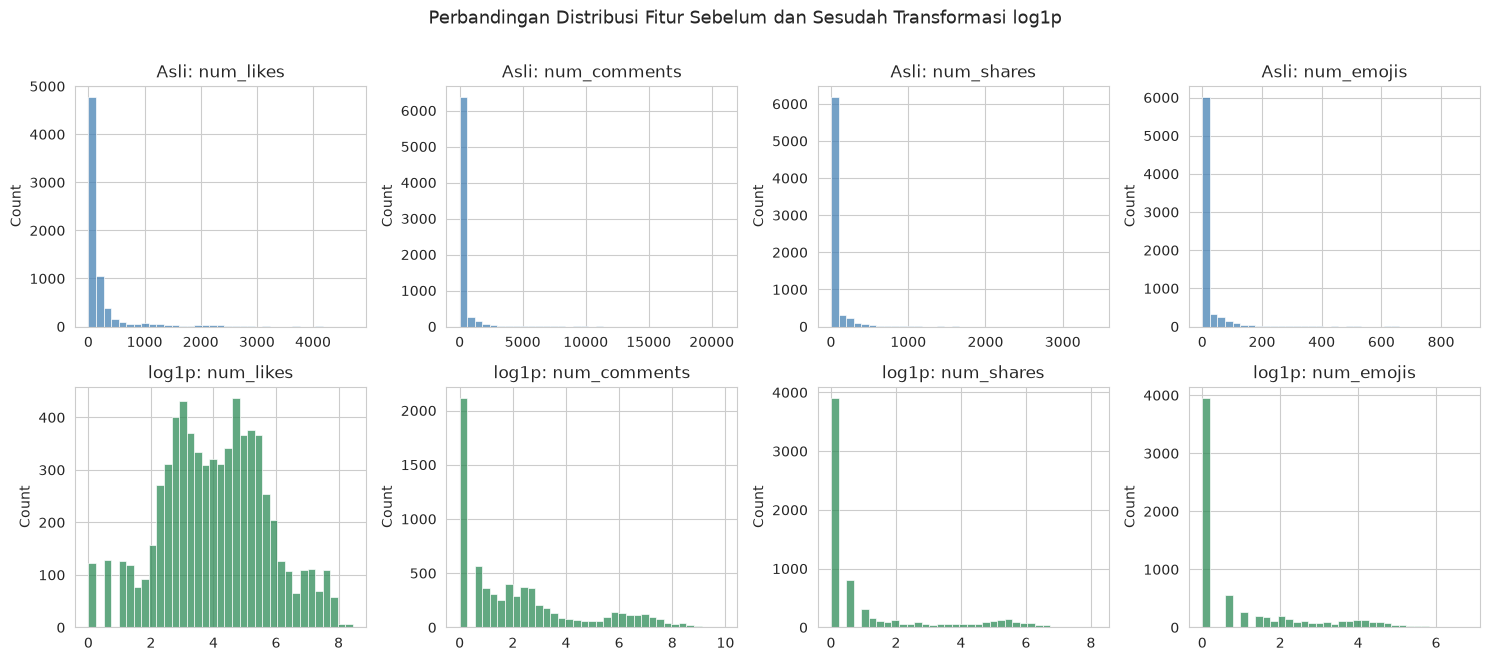

In [10]:
# Fitur hitungan pada dataset ini sangat miring (skewed). Terapkan transformasi log1p pada fitur yang dipilih.
# Tampilkan distribusi fitur sebelum dan sesudah transformasi untuk melihat perbedaannya.
X_log = np.log1p(X_raw)

skew_comp = pd.DataFrame({
    'skew_sebelum_log': X_raw.skew().round(2),
    'skew_sesudah_log1p': X_log.skew().round(2)
})
print('Perbandingan skewness sebelum dan sesudah log1p:')
print(skew_comp.to_string())

fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for i, col in enumerate(selected_features):
    sns.histplot(X_raw[col], bins=35, ax=axes[0, i], color='steelblue')
    axes[0, i].set_title(f'Asli: {col}')
    axes[0, i].set_xlabel('')

    sns.histplot(X_log[col], bins=35, ax=axes[1, i], color='seagreen')
    axes[1, i].set_title(f'log1p: {col}')
    axes[1, i].set_xlabel('')

plt.suptitle('Perbandingan Distribusi Fitur Sebelum dan Sesudah Transformasi log1p', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

In [11]:
# Lakukan feature scaling (misalnya StandardScaler) pada fitur hasil transformasi log dan simpan hasilnya (X_log_scaled).
# Simpan juga versi lain untuk keperluan perbandingan pada bagian 3.1:
# - X_raw: fitur mentah tanpa transformasi dan tanpa scaling
# - X_raw_scaled: fitur mentah dengan scaling saja
scaler_raw = StandardScaler()
X_raw_scaled = scaler_raw.fit_transform(X_raw)

scaler_log = StandardScaler()
X_log_scaled = scaler_log.fit_transform(X_log)

print('Ringkasan X_log_scaled (mean ~ 0, std ~ 1):')
print(pd.DataFrame(X_log_scaled, columns=selected_features).describe().loc[['mean', 'std', 'min', 'max']].round(4).to_string())

Ringkasan X_log_scaled (mean ~ 0, std ~ 1):
      num_likes  num_comments  num_shares  num_emojis
mean    -0.0000       -0.0000      0.0000     -0.0000
std      1.0001        1.0001      1.0001      1.0001
min     -2.4060       -0.9463     -0.6382     -0.6909
max      2.6216        3.3068      3.6673      3.6568


# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [12]:
# Latih K-Means dengan jumlah cluster yang sama (misalnya k=3) pada tiga versi data:
# (1) X_raw (mentah tanpa scaling), (2) X_raw_scaled (mentah dengan scaling), dan (3) X_log_scaled (log dan scaling).
# Gunakan random_state dan n_init yang sama agar perbandingan adil.
variants = {
    'X_raw (tanpa log & scaling)': X_raw.values,
    'X_raw_scaled (scaling saja)': X_raw_scaled,
    'X_log_scaled (log1p + scaling)': X_log_scaled
}

labels_31 = {}
for name, X_var in variants.items():
    km = KMeans(n_clusters=3, random_state=SEED, n_init=10)
    labels_31[name] = km.fit_predict(X_var)

In [13]:
# Bandingkan ketiga hasil tersebut: jumlah anggota tiap cluster dan Silhouette Score.
# Hitung Silhouette ketiganya pada ruang yang sama (misalnya X_log_scaled) agar perbandingannya adil.
# Amati fitur mana yang mendominasi varians pada data tanpa scaling, dan apakah ada cluster yang sangat kecil atau sangat besar.
rows = []
for name, lbl in labels_31.items():
    sil = silhouette_score(X_log_scaled, lbl)
    counts = pd.Series(lbl).value_counts().sort_index()
    counts_sorted = sorted([int(x) for x in counts.values], reverse=True)
    rows.append({
        'Versi Data': name,
        'Silhouette (ruang X_log_scaled)': round(sil, 4),
        'Ukuran Cluster (besar ke kecil)': str(counts_sorted),
        'Proporsi Cluster Terbesar (%)': round(counts_sorted[0] / len(lbl) * 100, 2)
    })

comp_31 = pd.DataFrame(rows)
print('Perbandingan K-Means (k=3) pada tiga versi preprocessing:')
print(comp_31.to_string(index=False))

print('\nVarians tiap fitur pada data mentah (X_raw):')
var_raw = X_raw.var()
var_df = pd.DataFrame({
    'Varians': var_raw.round(2),
    'Proporsi Total Varians (%)': (var_raw / var_raw.sum() * 100).round(2)
})
print(var_df.to_string())

Perbandingan K-Means (k=3) pada tiga versi preprocessing:
                    Versi Data  Silhouette (ruang X_log_scaled) Ukuran Cluster (besar ke kecil)  Proporsi Cluster Terbesar (%)
   X_raw (tanpa log & scaling)                           0.2731                [6392, 467, 137]                          91.37
   X_raw_scaled (scaling saja)                           0.2533                [6277, 373, 346]                          89.72
X_log_scaled (log1p + scaling)                           0.4638              [3607, 2258, 1131]                          51.56

Varians tiap fitur pada data mentah (X_raw):
                Varians  Proporsi Total Varians (%)
num_likes     193268.44                       19.13
num_comments  797310.07                       78.92
num_shares     17443.17                        1.73
num_emojis      2299.57                        0.23


## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [14]:
# Latih K-Means pada X_log_scaled untuk rentang k tertentu (misalnya k = 2 sampai 10).
# Simpan nilai inertia untuk setiap k.
k_range = list(range(2, 11))
inertias = []
kmeans_models = {}

for k in k_range:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    km.fit(X_log_scaled)
    inertias.append(km.inertia_)
    kmeans_models[k] = km

elbow_df = pd.DataFrame({'k': k_range, 'inertia': np.round(inertias, 2)})
elbow_df['penurunan_inertia'] = elbow_df['inertia'].shift(1) - elbow_df['inertia']
elbow_df['penurunan_persen (%)'] = (elbow_df['penurunan_inertia'] / elbow_df['inertia'].shift(1) * 100).round(2)
print(elbow_df.to_string(index=False))

 k  inertia  penurunan_inertia  penurunan_persen (%)
 2 11586.90                NaN                   NaN
 3  6779.84            4807.06                 41.49
 4  5678.25            1101.59                 16.25
 5  4739.96             938.29                 16.52
 6  4220.28             519.68                 10.96
 7  3772.10             448.18                 10.62
 8  3418.57             353.53                  9.37
 9  3116.43             302.14                  8.84
10  2899.05             217.38                  6.98


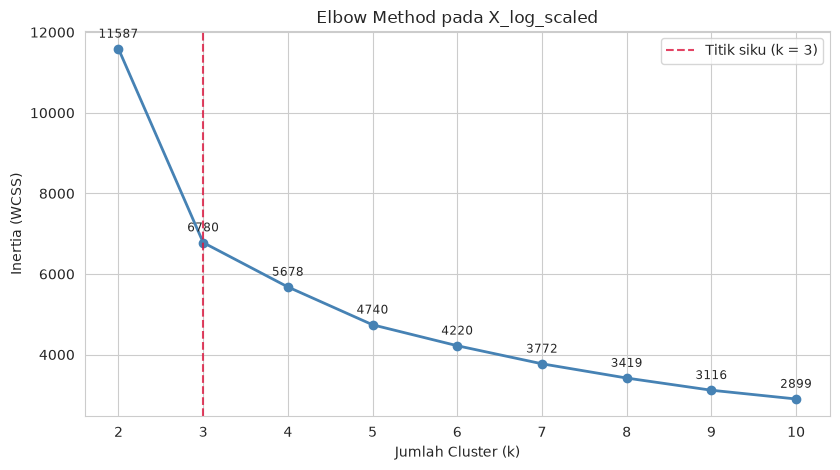

In [15]:
# Plot grafik Elbow (k vs inertia).
# Amati pada nilai k berapa terbentuk "siku".
# (Opsional) Gunakan library kneed (KneeLocator) untuk mendeteksi elbow secara otomatis, lalu bandingkan dengan pengamatan kalian.
plt.figure(figsize=(8.5, 4.8))
plt.plot(k_range, inertias, marker='o', linewidth=2, color='steelblue')
plt.axvline(x=3, color='crimson', linestyle='--', alpha=0.8, label='Titik siku (k = 3)')
for k, val in zip(k_range, inertias):
    plt.annotate(f'{val:.0f}', (k, val), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8.5)
plt.title('Elbow Method pada X_log_scaled')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Inertia (WCSS)')
plt.xticks(k_range)
plt.legend()
plt.tight_layout()
plt.show()

## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [16]:
# Hitung Silhouette Score untuk setiap nilai k pada rentang yang sama dengan Elbow Method.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.
sil_scores = []
ch_scores = []

for k in k_range:
    lbl = kmeans_models[k].labels_
    sil_scores.append(silhouette_score(X_log_scaled, lbl))
    ch_scores.append(calinski_harabasz_score(X_log_scaled, lbl))

sil_df = pd.DataFrame({
    'k': k_range,
    'silhouette_score': np.round(sil_scores, 4),
    'calinski_harabasz': np.round(ch_scores, 2)
})
print(sil_df.to_string(index=False))

 k  silhouette_score  calinski_harabasz
 2            0.5899            9897.49
 3            0.4638           10935.46
 4            0.3372            9155.54
 5            0.3586            8570.74
 6            0.3469            7871.98
 7            0.3367            7476.77
 8            0.3154            7173.71
 9            0.3293            6969.16
10            0.3160            6716.59


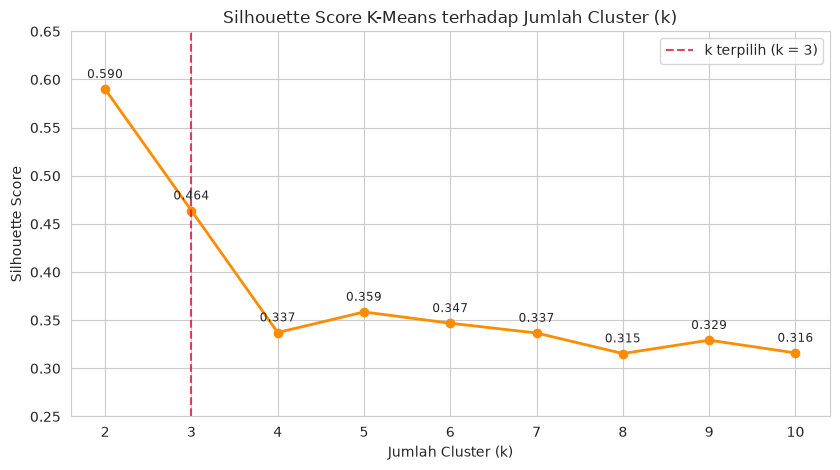

In [17]:
# Plot grafik Silhouette Score terhadap k.
# Tentukan nilai k terbaik dengan mempertimbangkan hasil Elbow Method dan Silhouette Score, lalu jelaskan alasannya pada cell markdown di bawah.
plt.figure(figsize=(8.5, 4.8))
plt.plot(k_range, sil_scores, marker='o', linewidth=2, color='darkorange')
plt.axvline(x=3, color='crimson', linestyle='--', alpha=0.8, label='k terpilih (k = 3)')
for k, val in zip(k_range, sil_scores):
    plt.annotate(f'{val:.3f}', (k, val), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8.5)
plt.title('Silhouette Score K-Means terhadap Jumlah Cluster (k)')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Silhouette Score')
plt.xticks(k_range)
plt.ylim(0.25, 0.65)
plt.legend()
plt.tight_layout()
plt.show()

Pilihan k untuk K-Means: `k = 3`.

Alasan: Pada grafik Elbow Method, penurunan inertia terbesar terjadi saat beralih dari `k = 2` (11.586,90) ke `k = 3` (6.779,84), yaitu turun sebesar 4.807,06 (41,49%). Setelah `k = 3`, penurunan inertia melandai drastis (hanya turun 1.101,59 atau 16,25% ke `k = 4`), sehingga titik siku terbentuk sangat jelas di `k = 3`. Meskipun Silhouette Score tertinggi berada di `k = 2` (0,5899), pembagian dua cluster terlalu kasar karena hanya memisahkan posting ber-engagement rendah dan tinggi. Pada `k = 3`, Silhouette Score masih cukup kuat (0,4638) dan Calinski-Harabasz Score justru mencapai nilai puncak (10.935,46), sekaligus menghasilkan tiga segmen engagement yang lebih informatif (pasif, menengah berbasis like, dan interaktif tinggi).

## 3.4 Model K-Means Final

In [18]:
# Latih model K-Means final dengan nilai k terbaik yang kalian pilih pada X_log_scaled.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
k_best = 3
kmeans_final = KMeans(n_clusters=k_best, random_state=SEED, n_init=10)
km_labels = kmeans_final.fit_predict(X_log_scaled)

print('Distribusi anggota cluster K-Means (k=3):')
km_counts = pd.Series(km_labels).value_counts().sort_index()
print(pd.DataFrame({
    'jumlah': km_counts,
    'persen (%)': (km_counts / len(km_labels) * 100).round(2)
}).to_string())

Distribusi anggota cluster K-Means (k=3):
   jumlah  persen (%)
0    1131       16.17
1    2258       32.28
2    3607       51.56


In [19]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
# Gunakan median karena distribusi fitur sangat miring.
# Ini membantu menginterpretasikan karakteristik tiap cluster.
km_profile_df = X_raw.copy()
km_profile_df['cluster'] = km_labels

km_median = km_profile_df.groupby('cluster')[selected_features].median()
km_median.insert(0, 'jumlah_posting', km_profile_df['cluster'].value_counts().sort_index())
km_median.insert(1, 'persen (%)', (km_median['jumlah_posting'] / len(km_profile_df) * 100).round(2))

km_mean = km_profile_df.groupby('cluster')[selected_features].mean().round(2)

print('Profil Cluster K-Means — MEDIAN (data asli):')
print(km_median.to_string())
print('\nProfil Cluster K-Means — RATA-RATA (data asli):')
print(km_mean.to_string())

Profil Cluster K-Means — MEDIAN (data asli):
         jumlah_posting  persen (%)  num_likes  num_comments  num_shares  num_emojis
cluster                                                                             
0                  1131       16.17      170.0         722.0       178.0        57.0
1                  2258       32.28      206.0          11.0         1.0         2.0
2                  3607       51.56       18.0           0.0         0.0         0.0

Profil Cluster K-Means — RATA-RATA (data asli):
         num_likes  num_comments  num_shares  num_emojis
cluster                                                 
0           304.50       1335.37      238.04       83.25
1           462.73         26.89        4.69        4.57
2            22.23          2.11        0.55        0.23


# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

In [20]:
# Hitung linkage matrix (scipy.cluster.hierarchy.linkage) dengan metode ward pada X_log_scaled.
# Dataset berisi sekitar 7.000 baris sehingga proses ini masih ringan dan tidak perlu dilakukan sampling.
Z_ward = linkage(X_log_scaled, method='ward')
print('Ukuran linkage matrix Z_ward:', Z_ward.shape)
print('5 jarak penggabungan terakhir (terbesar):', np.round(Z_ward[-5:, 2], 2))

Ukuran linkage matrix Z_ward: (6995, 4)
5 jarak penggabungan terakhir (terbesar): [ 37.54  42.31  48.41 103.7  175.13]


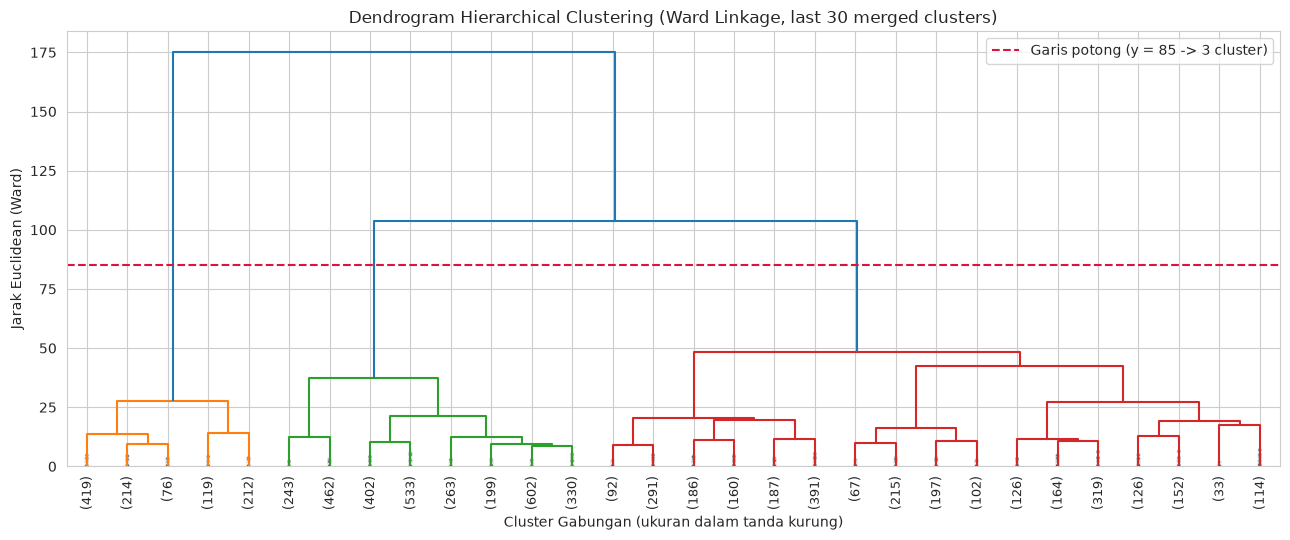

In [21]:
# Tampilkan dendrogram dari linkage matrix di atas.
# Batasi tampilan agar mudah dibaca (misalnya truncate_mode='lastp' atau p=30).
# Amati pada ketinggian berapa sebaiknya dendrogram dipotong untuk menentukan jumlah cluster.
plt.figure(figsize=(13, 5.5))
dendrogram(
    Z_ward,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=9,
    show_contracted=True,
    color_threshold=85
)
plt.axhline(y=85, color='crimson', linestyle='--', linewidth=1.5, label='Garis potong (y = 85 -> 3 cluster)')
plt.title('Dendrogram Hierarchical Clustering (Ward Linkage, last 30 merged clusters)')
plt.xlabel('Cluster Gabungan (ukuran dalam tanda kurung)')
plt.ylabel('Jarak Euclidean (Ward)')
plt.legend()
plt.tight_layout()
plt.show()

## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [22]:
# Latih AgglomerativeClustering dengan masing-masing linkage (ward, complete, average, single).
# Gunakan jumlah cluster yang sama untuk semua linkage agar perbandingan adil.
linkage_methods = ['ward', 'complete', 'average', 'single']
hc_labels_dict = {}

for method in linkage_methods:
    hc = AgglomerativeClustering(n_clusters=k_best, linkage=method)
    hc_labels_dict[method] = hc.fit_predict(X_log_scaled)

In [23]:
# Hitung Silhouette Score untuk setiap linkage dan tampilkan jumlah anggota tiap cluster.
# Sajikan dalam satu tabel perbandingan.
# Amati apakah ada linkage yang menghasilkan cluster sangat tidak seimbang (misalnya satu cluster sangat besar dan lainnya hanya beberapa titik).
link_rows = []
for method, lbl in hc_labels_dict.items():
    sil = silhouette_score(X_log_scaled, lbl)
    dbi = davies_bouldin_score(X_log_scaled, lbl)
    ch = calinski_harabasz_score(X_log_scaled, lbl)
    counts = sorted([int(x) for x in pd.Series(lbl).value_counts().values], reverse=True)
    link_rows.append({
        'Linkage': method,
        'Silhouette': round(sil, 4),
        'Davies-Bouldin': round(dbi, 4),
        'Calinski-Harabasz': round(ch, 2),
        'Ukuran Cluster (besar ke kecil)': str(counts),
        'Cluster Terbesar (%)': round(counts[0] / len(lbl) * 100, 2)
    })

link_comp_df = pd.DataFrame(link_rows)
print('Perbandingan Metode Linkage pada Hierarchical Clustering (k=3):')
print(link_comp_df.to_string(index=False))

Perbandingan Metode Linkage pada Hierarchical Clustering (k=3):
 Linkage  Silhouette  Davies-Bouldin  Calinski-Harabasz Ukuran Cluster (besar ke kecil)  Cluster Terbesar (%)
    ward      0.4201          0.8329            9959.19              [3034, 2922, 1040]                 43.37
complete      0.2437          0.9022            4234.38               [3904, 2632, 460]                 55.80
 average      0.5069          0.5221            4856.53                [5764, 1197, 35]                 82.39
  single      0.3139          0.4851               3.47                    [6994, 1, 1]                 99.97


Pilihan linkage untuk Hierarchical Clustering: `ward`.

Alasan: `ward` menghasilkan pembagian cluster yang seimbang (`[3034, 2922, 1040]`), memiliki Silhouette Score yang solid (0,4201), serta Calinski-Harabasz Score tertinggi jauh melampaui linkage lain (9.959,19). Meskipun `average` memiliki Silhouette Score tertinggi (0,5069) dan Davies-Bouldin lebih kecil (0,5221), pembagiannya sangat timpang (`[5764, 1197, 35]`) karena satu cluster hanya berisi 35 titik ekstrem sementara 82,39% data menumpuk dalam satu cluster. Sementara itu, `single` mengalami *chaining effect* ekstrem (`[6994, 1, 1]`), dan `complete` memiliki Silhouette terendah (0,2437) dengan Davies-Bouldin terbesar (0,9022).

## 4.3 Model Hierarchical Clustering Final

In [24]:
# Latih model AgglomerativeClustering final dengan linkage terbaik dan jumlah cluster yang sama dengan K-Means final.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
hc_final = AgglomerativeClustering(n_clusters=k_best, linkage='ward')
hc_labels = hc_final.fit_predict(X_log_scaled)

print('Distribusi anggota cluster Hierarchical Clustering (Ward, k=3):')
hc_counts = pd.Series(hc_labels).value_counts().sort_index()
print(pd.DataFrame({
    'jumlah': hc_counts,
    'persen (%)': (hc_counts / len(hc_labels) * 100).round(2)
}).to_string())

Distribusi anggota cluster Hierarchical Clustering (Ward, k=3):
   jumlah  persen (%)
0    2922       41.77
1    1040       14.87
2    3034       43.37


In [25]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
hc_profile_df = X_raw.copy()
hc_profile_df['cluster'] = hc_labels

hc_median = hc_profile_df.groupby('cluster')[selected_features].median()
hc_median.insert(0, 'jumlah_posting', hc_profile_df['cluster'].value_counts().sort_index())
hc_median.insert(1, 'persen (%)', (hc_median['jumlah_posting'] / len(hc_profile_df) * 100).round(2))

hc_mean = hc_profile_df.groupby('cluster')[selected_features].mean().round(2)

print('Profil Cluster Hierarchical (Ward) — MEDIAN (data asli):')
print(hc_median.to_string())
print('\nProfil Cluster Hierarchical (Ward) — RATA-RATA (data asli):')
print(hc_mean.to_string())

Profil Cluster Hierarchical (Ward) — MEDIAN (data asli):
         jumlah_posting  persen (%)  num_likes  num_comments  num_shares  num_emojis
cluster                                                                             
0                  2922       41.77      150.0           9.0         1.0         1.0
1                  1040       14.87      168.0         815.5       193.5        60.5
2                  3034       43.37       14.0           0.0         0.0         0.0

Profil Cluster Hierarchical (Ward) — RATA-RATA (data asli):
         num_likes  num_comments  num_shares  num_emojis
cluster                                                 
0           386.75         29.40        5.27        4.48
1           277.53       1430.19      255.40       88.24
2            16.71          1.76        0.25        0.15


# 5. Evaluasi Model

In [26]:
# Hitung metrik evaluasi INTERNAL untuk K-Means dan Hierarchical Clustering:
# Silhouette Score (semakin tinggi semakin baik), Davies-Bouldin Index (semakin rendah semakin baik), dan Calinski-Harabasz Score (semakin tinggi semakin baik).
# Sajikan dalam satu tabel perbandingan.
eval_rows = []
for name, lbl in [('K-Means (k=3)', km_labels), ('Hierarchical - Ward (k=3)', hc_labels)]:
    eval_rows.append({
        'Model': name,
        'Silhouette Score (tinggi=baik)': round(silhouette_score(X_log_scaled, lbl), 4),
        'Davies-Bouldin Index (rendah=baik)': round(davies_bouldin_score(X_log_scaled, lbl), 4),
        'Calinski-Harabasz Score (tinggi=baik)': round(calinski_harabasz_score(X_log_scaled, lbl), 2)
    })

eval_df = pd.DataFrame(eval_rows)
print('Perbandingan Metrik Evaluasi Internal:')
print(eval_df.to_string(index=False))

Perbandingan Metrik Evaluasi Internal:
                    Model  Silhouette Score (tinggi=baik)  Davies-Bouldin Index (rendah=baik)  Calinski-Harabasz Score (tinggi=baik)
            K-Means (k=3)                          0.4638                              0.8302                               10935.46
Hierarchical - Ward (k=3)                          0.4201                              0.8329                                9959.19


Varians dijelaskan PC1: 75.87%
Varians dijelaskan PC2: 15.95%
Total varians 2 komponen PCA: 91.82%


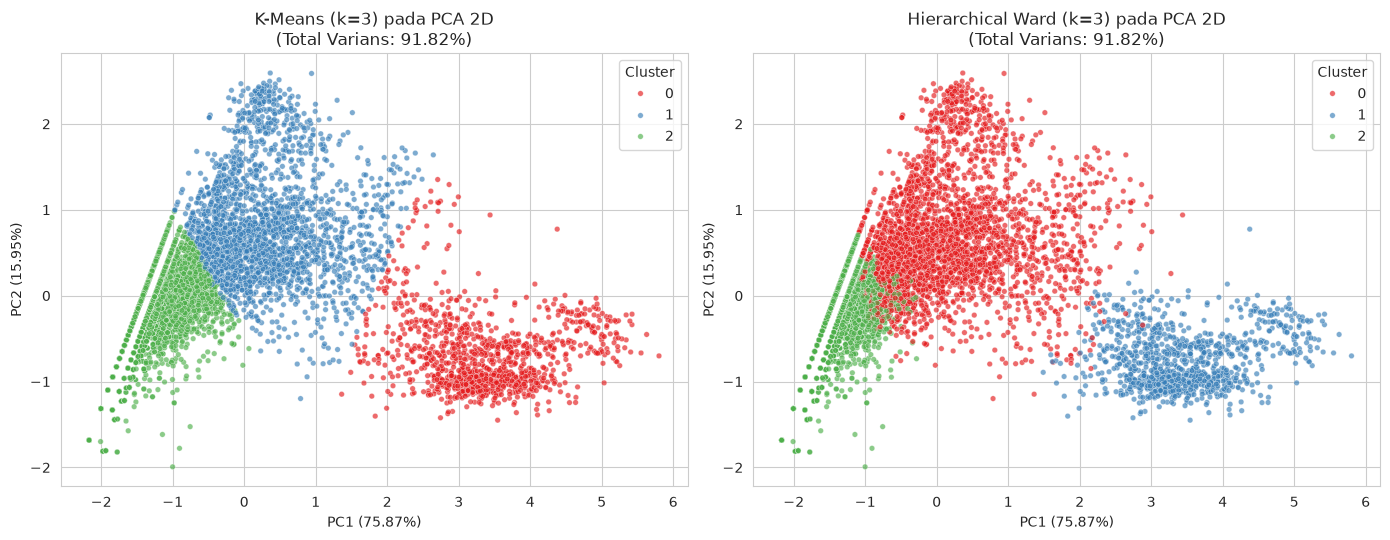

In [27]:
# Lakukan PCA ke 2 komponen pada X_log_scaled.
# Tampilkan scatter plot hasil clustering K-Means dan Hierarchical Clustering dalam satu baris subplot, diwarnai berdasarkan label cluster.
# Tampilkan juga persentase varians yang dijelaskan oleh kedua komponen PCA.
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_log_scaled)
var_ratio = pca.explained_variance_ratio_ * 100

print(f'Varians dijelaskan PC1: {var_ratio[0]:.2f}%')
print(f'Varians dijelaskan PC2: {var_ratio[1]:.2f}%')
print(f'Total varians 2 komponen PCA: {var_ratio.sum():.2f}%')

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
palette = sns.color_palette('Set1', n_colors=k_best)

sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1], hue=km_labels,
    palette=palette, s=16, alpha=0.65, ax=axes[0]
)
axes[0].set_title(f'K-Means (k=3) pada PCA 2D\n(Total Varians: {var_ratio.sum():.2f}%)')
axes[0].set_xlabel(f'PC1 ({var_ratio[0]:.2f}%)')
axes[0].set_ylabel(f'PC2 ({var_ratio[1]:.2f}%)')
axes[0].legend(title='Cluster')

sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1], hue=hc_labels,
    palette=palette, s=16, alpha=0.65, ax=axes[1]
)
axes[1].set_title(f'Hierarchical Ward (k=3) pada PCA 2D\n(Total Varians: {var_ratio.sum():.2f}%)')
axes[1].set_xlabel(f'PC1 ({var_ratio[0]:.2f}%)')
axes[1].set_ylabel(f'PC2 ({var_ratio[1]:.2f}%)')
axes[1].legend(title='Cluster')

plt.tight_layout()
plt.show()

Komposisi status_type (%) — K-Means:
status_type  link  photo  status  video
row_0                                  
0            0.00   4.60    0.97  94.43
1            1.11  65.32   10.41  23.16
2            1.05  75.27    3.13  20.54

Komposisi status_type (%) — Hierarchical (Ward):
status_type  link  photo  status  video
row_0                                  
0            1.27  65.33   10.10  23.31
1            0.00   0.87    0.00  99.13
2            0.86  76.60    2.11  20.44


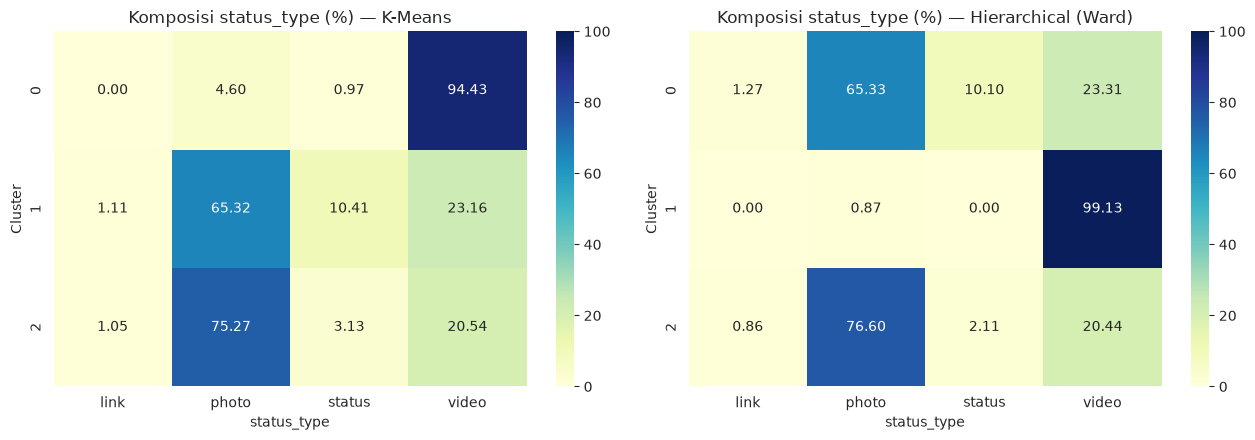

In [28]:
# Tampilkan komposisi status_type pada tiap cluster (crosstab dalam persen) untuk K-Means dan Hierarchical Clustering dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
# Ini hanya untuk membantu interpretasi cluster, bukan sebagai label asli.
km_ct = pd.crosstab(km_labels, meta_df['status_type'], normalize='index') * 100
hc_ct = pd.crosstab(hc_labels, meta_df['status_type'], normalize='index') * 100

print('Komposisi status_type (%) — K-Means:')
print(km_ct.round(2).to_string())
print('\nKomposisi status_type (%) — Hierarchical (Ward):')
print(hc_ct.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(km_ct, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=100, ax=axes[0])
axes[0].set_title('Komposisi status_type (%) — K-Means')
axes[0].set_xlabel('status_type')
axes[0].set_ylabel('Cluster')

sns.heatmap(hc_ct, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=100, ax=axes[1])
axes[1].set_title('Komposisi status_type (%) — Hierarchical (Ward)')
axes[1].set_xlabel('status_type')
axes[1].set_ylabel('Cluster')

plt.tight_layout()
plt.show()

# 6. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Jelaskan pengaruh transformasi log dan feature scaling pada K-Means berdasarkan hasil pada bagian 3.1. Mengapa keduanya penting pada algoritma berbasis jarak, terutama untuk data yang sangat miring dan mengandung outlier ekstrem?
- Bagaimana kalian menangani kolom yang redundan atau banyak bernilai nol (misalnya reaksi emoji)? Jelaskan alasan pemilihan fitur kalian.
- Berapa jumlah cluster optimal menurut Elbow Method dan Silhouette Score? Apakah keduanya menghasilkan kesimpulan yang sama? Jika berbeda, mana yang kalian pilih dan mengapa?
- Bandingkan hasil keempat metode linkage pada Hierarchical Clustering. Linkage mana yang paling baik dan mengapa? Bagaimana karakteristik cluster yang dihasilkan oleh single linkage?
- Bandingkan performa K-Means vs Hierarchical Clustering berdasarkan metrik internal dan visualisasi PCA. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian?
- Bagaimana karakteristik tiap cluster berdasarkan profil median fitur dan komposisi status_type? Beri nama atau julukan yang menggambarkan tiap cluster.
- Apa kelebihan dan kekurangan masing-masing metode (misalnya dari sisi kebutuhan menentukan k di awal, bentuk cluster, dan kebutuhan waktu serta memori)?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.

### Pembahasan Analisis

Kualitas hasil clustering pada dataset `Live.csv` ternyata sangat ditentukan sejak tahap pemilihan fitur dan prapemrosesan data. Setelah empat kolom kosong (`Column1`–`Column4`) dan 54 baris duplikat (dengan `status_id` berbeda) dihapus hingga menyisakan 6.996 posting, langkah pertama yang krusial adalah mencegah distorsi ruang fitur. Kolom `num_reactions` dibuang karena bersifat redundan—nilainya secara definisi merupakan penjumlahan dari `num_likes` dan lima reaksi emoji serta berkorelasi 0,9949 dengan `num_likes`—sehingga mempertahankannya akan menyebabkan bobot reaksi terhitung ganda dalam perhitungan jarak. Di sisi lain, kelima kolom reaksi emoji (`num_loves`, `num_wows`, `num_hahas`, `num_sads`, `num_angrys`) sangat jarang terisi (*sparse*), dengan proporsi nol antara 60,00% hingga 94,00% dan seluruhnya bernilai nol pada periode 2012–2015 sebelum fitur reaksi diluncurkan Facebook. Menggabungkannya menjadi satu fitur `num_emojis` menghasilkan empat fitur yang setara dan tidak saling tumpang tindih: `num_likes`, `num_comments`, `num_shares`, dan `num_emojis`.

Pemilihan fitur yang bersih tersebut tetap belum cukup apabila data langsung dimasukkan ke K-Means tanpa transformasi skala yang tepat. Hasil eksperimen pada bagian 3.1 memperlihatkan bahwa pada data mentah (`X_raw`), K-Means gagal membagi data secara proporsional: Silhouette Score (diukur pada ruang `X_log_scaled`) hanya mencapai 0,2731, dengan 6.392 dari 6.996 posting (91,37%) menumpuk pada satu cluster sementara dua cluster sisanya hanya menampung 467 dan 137 posting ekstrem. Hal ini terjadi karena algoritma berbasis jarak Euclidean sangat sensitif terhadap perbedaan skala dan varians; pada data mentah, jarak didominasi oleh `num_comments` (78,92% total varians) dan `num_likes` (19,13%), sedangkan `num_shares` (1,73%) dan `num_emojis` (0,23%) hampir tidak berpengaruh. Menariknya, penerapan `StandardScaler` saja tanpa transformasi log (`X_raw_scaled`) tidak menyelesaikan persoalan ini—Silhouette Score justru turun menjadi 0,2533 dan cluster terbesar masih menampung 6.277 posting (89,72%). Penyebabnya adalah distribusi fitur hitungan yang sangat miring ke kanan (*skewness* 3,93 hingga 8,99) dengan outlier ekstrem seperti 20.990 komentar; scaling linear tetap menyisakan ekor panjang yang menarik centroid ke arah segelintir posting viral. Baru setelah transformasi `log1p` diterapkan untuk menekan skewness ke rentang -0,01 hingga 1,53 lalu dilanjutkan dengan `StandardScaler` (`X_log_scaled`), seluruh fitur berkontribusi secara seimbang, Silhouette Score melonjak menjadi 0,4638, dan distribusi anggota cluster menjadi jauh lebih proporsional (`[3607, 2258, 1131]`).

Pada ruang `X_log_scaled` tersebut, penentuan jumlah cluster optimal menunjukkan perbedaan indikasi antara Elbow Method dan Silhouette Score. Grafik Elbow memperlihatkan penurunan inertia paling tajam terjadi dari `k = 2` (11.586,90) ke `k = 3` (6.779,84) sebesar 41,49%, kemudian melandai pada `k = 4` (5.678,25, turun 16,25%) dan nilai `k` selanjutnya, sehingga titik siku tampak jelas pada `k = 3`. Sebaliknya, Silhouette Score mencapai nilai tertinggi pada `k = 2` (0,5899), lalu berada di posisi kedua pada `k = 3` (0,4638) sebelum turun tajam ke 0,3372 pada `k = 4`. Meski demikian, `k = 3` dipilih sebagai jumlah cluster paling tepat karena `k = 2` hanya memecah data secara terlalu kasar menjadi engagement rendah dan tinggi. Pilihan `k = 3` tidak hanya konsisten dengan titik siku Elbow Method, tetapi juga didukung oleh puncak Calinski-Harabasz Score (10.935,46) serta mampu membedakan perilaku audiens yang secara substansi memang terbagi ke dalam tiga pola berbeda.

Pengujian pada Hierarchical Clustering dengan `k = 3` memperlihatkan betapa besar pengaruh metode *linkage* terhadap struktur cluster yang terbentuk. Di antara keempat variasi, `ward` linkage memberikan hasil paling baik secara keseluruhan dengan Silhouette Score 0,4201, Davies-Bouldin 0,8329, Calinski-Harabasz 9.959,19, serta ukuran cluster yang seimbang (`[3034, 2922, 1040]`). Keunggulan ini lahir dari mekanisme `ward` yang meminimalkan kenaikan varians internal pada setiap tahap penggabungan, sehingga cenderung membentuk kelompok yang kompak. Sebaliknya, meskipun `average` linkage mencatat Silhouette Score tertinggi (0,5069), pembagian anggotanya sangat timpang (`[5764, 1197, 35]`) karena satu cluster kecil hanya mengisolasi 35 outlier sementara 82,39% data digabungkan menjadi satu—sebuah bukti bahwa metrik Silhouette tinggi tidak otomatis mencerminkan segmentasi yang bermanfaat. Metode `complete` linkage menghasilkan Silhouette terendah (0,2437) dengan batas antarkelompok yang kurang rapi, sedangkan `single` linkage mengalami *chaining effect* ekstrem (`[6994, 1, 1]`): karena jarak antarcluster dihitung dari pasangan titik terdekat, hampir seluruh titik saling bertautan menjadi satu rantai besar dan hanya menyisakan dua outlier sebagai cluster tunggal.

Ketika K-Means dibandingkan langsung dengan Hierarchical Clustering (`ward`), performa K-Means sedikit lebih unggul pada seluruh metrik internal di ruang `X_log_scaled`: Silhouette Score 0,4638 berbanding 0,4201, Davies-Bouldin 0,8302 berbanding 0,8329, dan Calinski-Harabasz 10.935,46 berbanding 9.959,19. Namun, secara substansi kedua metode tidak menghasilkan pemisahan yang berbeda jauh. Proyeksi PCA 2D yang menjelaskan 91,82% varians total (PC1 75,87% dan PC2 15,95%) memperlihatkan struktur tiga kelompok yang hampir identik, dengan perbedaan utama hanya berada di wilayah perbatasan antara cluster engagement rendah dan menengah. K-Means sedikit lebih optimal pada metrik berbasis varians karena mampu memperbarui posisi centroid dan memindahkan keanggotaan titik secara iteratif hingga konvergen, sedangkan Agglomerative Clustering bekerja secara *greedy* sehingga keputusan penggabungan pada tahap awal bersifat permanen dan tidak dapat dikoreksi kembali.

Keselarasan kedua metode juga tampak nyata saat profil median fitur dan komposisi `status_type` dianalisis, meskipun `status_type` sama sekali tidak dilibatkan dalam perhitungan jarak. Kelompok pertama dapat dijuluki sebagai Segmen Video Live Selling / Interaksi Tinggi (K-Means Cluster 0 dengan 1.131 posting; Ward Cluster 1 dengan 1.040 posting), yang ditandai oleh median komentar sangat tinggi (722 pada K-Means; 815,5 pada Ward), share tinggi (178; 193,5), emoji tinggi (57; 60,5), serta like yang besar (170; 168), dengan dominasi tipe `video` sebesar 94,43% pada K-Means dan 99,13% pada Ward—mencerminkan sesi *Facebook Live selling* yang memicu percakapan langsung pembeli. Kelompok kedua adalah Segmen Populer Berbasis Like / Engagement Menengah (K-Means Cluster 1 dengan 2.258 posting; Ward Cluster 0 dengan 2.922 posting), yang memperoleh like tinggi (median 206 pada K-Means; 150 pada Ward) namun rendah dalam komentar (11; 9), share (1; 1), dan emoji (2; 1); mayoritasnya berupa `photo` (65,32%–65,33%) dan `status` (10,10%–10,41%), khas unggahan katalog foto atau promosi yang banyak disukai secara pasif tanpa banyak diskusi. Sementara itu, kelompok ketiga merupakan Segmen Engagement Rendah / Pasif (K-Means Cluster 2 dengan 3.607 posting; Ward Cluster 2 dengan 3.034 posting), yang hanya mencatat median like 18 (K-Means) atau 14 (Ward) dengan median komentar, share, dan emoji seluruhnya nol, serta didominasi `photo` (75,27%–76,60%) sebagai representasi unggahan rutin yang minim respons audiens.

Dari seluruh rangkaian eksperimen tersebut, terlihat jelas perbedaan kekuatan dan keterbatasan kedua metode. K-Means unggul dari sisi kecepatan dan efisiensi memori dengan kompleksitas $O(n \cdot k \cdot d \cdot t)$, mudah diskalakan ke dataset berukuran besar, serta secara langsung mengoptimalkan kekompakan varians dalam cluster; kekurangannya, jumlah cluster `k` harus ditetapkan sebelum pelatihan, hasilnya dapat dipengaruhi inisialisasi centroid (meski dapat diredam dengan `n_init`), dan bentuk cluster diasumsikan cenderung bulat atau konveks. Sebaliknya, Hierarchical Clustering tidak menuntut penentuan `k` di awal karena keseluruhan hierarki penggabungan dapat ditinjau terlebih dahulu melalui dendrogram, hasilnya bersifat deterministik tanpa pengaruh inisialisasi acak, dan pilihan *linkage* memberi fleksibilitas terhadap bentuk cluster. Namun, kebutuhan memori dan waktu komputasinya jauh lebih besar karena matriks jarak berorde $O(n^2)$ sehingga sulit diterapkan pada ratusan ribu data, ditambah sifat penggabungan permanen yang membuat kesalahan pengelompokan di tahap awal tidak dapat diperbaiki.

# 7. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya melakukan clustering terpisah untuk periode sebelum dan sesudah tahun 2016, memanfaatkan fitur waktu seperti jam atau hari posting, mencoba algoritma clustering lain seperti DBSCAN atau Gaussian Mixture Model, melakukan reduksi dimensi sebelum clustering, atau mencoba variasi hyperparameter lain seperti n_init dan init pada K-Means), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

### Kesimpulan dan Saran

Eksperimen pada dataset `Live.csv` (6.996 posting bersih setelah menghapus 4 kolom kosong dan 54 duplikat) menunjukkan bahwa tahap preprocessing sangat menentukan kualitas clustering. Kombinasi penghapusan fitur redundan (`num_reactions`), penggabungan reaksi emoji sparse menjadi `num_emojis`, transformasi `log1p`, dan `StandardScaler` berhasil menaikkan Silhouette Score K-Means (`k = 3`) dari 0,2731 (data mentah) menjadi 0,4638 dan mencegah penumpukan lebih dari 90% data ke dalam satu cluster.

Jumlah cluster `k = 3` menjadi pilihan paling masuk akal berdasarkan titik siku Elbow Method, puncak Calinski-Harabasz Score (10.935,46), dan keseimbangan interpretasi. Pada Hierarchical Clustering, `ward` linkage jauh lebih baik dibanding `complete`, `average`, dan `single` karena membentuk tiga cluster seimbang tanpa terjebak isolasi outlier maupun *chaining effect*. Secara metrik internal, K-Means sedikit lebih unggul dari Hierarchical Ward (Silhouette 0,4638 vs 0,4201; Davies-Bouldin 0,8302 vs 0,8329; Calinski-Harabasz 10.935,46 vs 9.959,19), namun keduanya konsisten membagi posting ke dalam tiga profil nyata: Video Live Selling berinteraksi tinggi (>94% video), Posting Populer Berbasis Like, dan Posting Engagement Rendah.

Untuk eksperimen lanjutan, disarankan beberapa hal berikut:
1. Memisahkan analisis clustering untuk periode sebelum tahun 2016 dan mulai tahun 2016 ke atas, agar ketiadaan fitur reaksi emoji sebelum 2016 tidak bercampur dengan posting yang memang tidak mendapat reaksi emoji setelah 2016.
2. Menambahkan fitur waktu dari `status_published` seperti jam posting dan hari dalam seminggu untuk melihat apakah jadwal unggah berkaitan dengan segmen engagement tinggi.
3. Mencoba algoritma lain seperti Gaussian Mixture Model (GMM) untuk melihat probabilitas keanggotaan pada perbatasan cluster pasif dan menengah, serta DBSCAN atau HDBSCAN untuk memisahkan posting viral ekstrem secara eksplisit sebagai outlier.